In [ ]:
!pip install -q "dask[complete]" psutil pyarrow

In [ ]:
import psutil, os
print("RAM (GB):", round(psutil.virtual_memory().total / 1e9, 1))
print("CPU cores:", os.cpu_count())
print("Disk free (GB):", round(psutil.disk_usage('/content').free / 1e9, 1))

RAM (GB): 13.6
CPU cores: 2
Disk free (GB): 87.7


In [ ]:
import numpy as np, pandas as pd, os

FILE = "/content/big_data.csv"
TARGET = 5.5 * 1024**3        # Required size (increase to 8 if you want guaranteed OOM)
cats = np.array(["electronics", "clothing", "grocery", "toys", "books", "sports"])
rng = np.random.default_rng(42)

if os.path.exists(FILE): os.remove(FILE)
n, i, header = 2_000_000, 0, True

while not os.path.exists(FILE) or os.path.getsize(FILE) < TARGET:
    df = pd.DataFrame({
        "id": np.arange(i*n, (i+1)*n),
        "price": rng.uniform(1, 1000, n).round(2),
        "quantity": rng.integers(1, 20, n),
        "category": rng.choice(cats, n),
        "rating": rng.uniform(1, 5, n).round(3),
        "user_id": rng.integers(1, 5_000_000, n),
    })
    df.to_csv(FILE, mode="a", header=header, index=False)
    header = False; i += 1

print("File size (GB):", round(os.path.getsize(FILE) / 1024**3, 2))

حجم الملف (GB): 5.52


In [ ]:
import pandas as pd, psutil
print("RAM Before:", psutil.virtual_memory().percent, "%")
df = pd.read_csv("/content/big_data.csv")

RAM قبل: 15.1 %


In [ ]:
  import os
  print(os.path.exists("/content/big_data.csv"))

True


In [ ]:
import subprocess, sys

code = """
import resource, pandas as pd
resource.setrlimit(resource.RLIMIT_AS, (6*1024**3, 6*1024**3))
df = pd.read_csv('/content/big_data.csv')
"""
r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
print(r.stderr[-400:])     # فيها MemoryError

rs.TextReader._convert_column_data
  File "parsers.pyx", line 1120, in pandas._libs.parsers.TextReader._convert_tokens
  File "parsers.pyx", line 1222, in pandas._libs.parsers.TextReader._convert_with_dtype
  File "parsers.pyx", line 1833, in pandas._libs.parsers._try_int64
numpy._core._exceptions._ArrayMemoryError: Unable to allocate 1.00 MiB for an array with shape (131072,) and data type int64



In [ ]:
import threading, time, psutil

class Measure:
    def __enter__(self):
        self.peak, self._on = 0, True
        self.base = psutil.virtual_memory().used
        self.t = threading.Thread(target=self._watch, daemon=True)
        self.t.start(); self.t0 = time.time(); return self
    def _watch(self):
        while self._on:
            self.peak = max(self.peak, psutil.virtual_memory().used)
            time.sleep(0.2)
    def __exit__(self, *a):
        self._on = False; self.t.join()
        self.seconds = time.time() - self.t0
        self.peak_gb = (self.peak - self.base) / 1e9    # Increase above baseline memory


In [ ]:
import pandas as pd
FILE = "/content/big_data.csv"

total_sum, total_count = 0.0, 0
cat_sum = pd.Series(dtype="float64")

with Measure() as m_chunk:
    for chunk in pd.read_csv(FILE, chunksize=100_000):
        total_sum   += chunk["price"].sum()
        total_count += chunk["price"].count()
        cat_sum = cat_sum.add(chunk.groupby("category")["price"].sum(), fill_value=0)

print("Total:", total_sum)
print("Overall Average:", total_sum / total_count)
print(cat_sum)
print("Time:", round(m_chunk.seconds, 1), "seconds")
print("Peak extra RAM:", round(m_chunk.peak_gb, 2), "GB")

المجموع: 74072191117.82997
المتوسط العام: 500.48777782317546
category
books          1.235139e+10
clothing       1.234793e+10
electronics    1.234231e+10
grocery        1.234196e+10
sports         1.234588e+10
toys           1.234273e+10
dtype: float64
الوقت: 128.6 ثانية
أقصى ذاكرة إضافية: 0.07 GB


In [ ]:
import dask, dask.dataframe as dd
from dask.distributed import Client

# 2 workers (based on Colab cores) and memory limit per worker
client = Client(n_workers=2, threads_per_worker=1, memory_limit="5GB")

ddf = dd.read_csv(FILE, blocksize="128MB")
print("Number of partitions:", ddf.npartitions)

lazy_mean = ddf["price"].mean()
print(lazy_mean)                  # Deferred object, computation hasn't run yet

with Measure() as m_dask:
    result = lazy_mean.compute()  # Actual execution starts here

print("Average:", result)
print("Time:", round(m_dask.seconds, 1), "seconds")
print("Peak extra RAM:", round(m_dask.peak_gb, 2), "GB")

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:46717
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:39789'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:45843'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:41623 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:41623
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:49068
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:32779 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:32779
INFO:distributed.core:Starting established connection to tcp://127

عدد الأقسام: 46
<dask_expr.expr.Scalar: expr=ArrowStringConversion(frame=FromMapProjectable(dad2b96))['price'].mean(), dtype=float64>
المتوسط: 500.4877778231757
الوقت: 139.2 ثانية
أقصى ذاكرة إضافية: 5.9 GB


In [ ]:
# 1) Plot diagram (if error occurs: !apt-get -qq install graphviz)
lazy_mean.visualize(filename="graph.png")

# 2) Read required columns only
ddf2 = dd.read_csv(FILE, usecols=["price", "category"], blocksize="128MB")

# 3) Multiple results in a single pass over the file
mean_, sum_, by_cat = dask.compute(
    ddf2["price"].mean(),
    ddf2["price"].sum(),
    ddf2.groupby("category")["price"].mean(),
)

# 4) Convert CSV to Parquet (pyarrow benefit)
ddf.to_parquet("/content/data_parquet", engine="pyarrow")
pq = dd.read_parquet("/content/data_parquet", columns=["price"])
with Measure() as m_pq:
    pq["price"].mean().compute()
print("Parquet:", round(m_pq.seconds, 1), "seconds")

Parquet: 17.7 ثانية


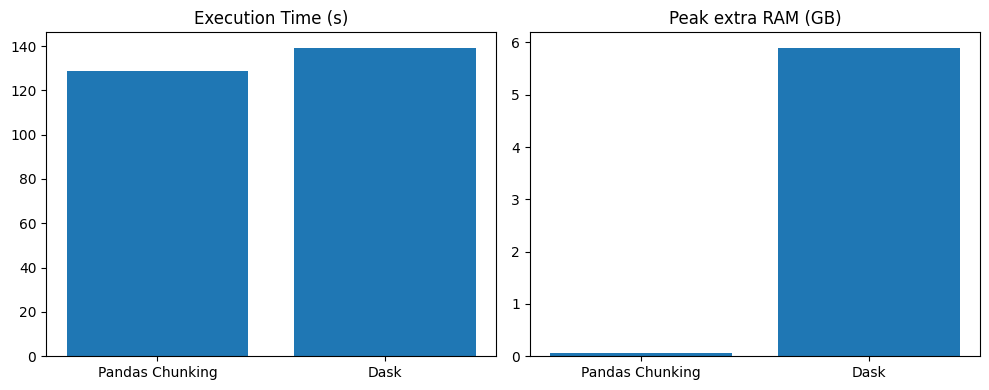

In [ ]:
import matplotlib.pyplot as plt

methods = ["Pandas Chunking", "Dask"]
times = [m_chunk.seconds, m_dask.seconds]
mems  = [m_chunk.peak_gb, m_dask.peak_gb]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(methods, times); ax[0].set_title("Execution Time (s)")
ax[1].bar(methods, mems);  ax[1].set_title("Peak extra RAM (GB)")
plt.tight_layout(); plt.savefig("benchmark.png", dpi=150); plt.show()